# NovaRetail+: Factores de comportamiento asociados al ingreso anual

**Caso de negocio simulado del bootcamp de Data Analytics de TripleTen.** Los datos son ficticios.

**Pregunta de negocio:** ¿qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual?

**Datos:** 15,000 clientes y 12 columnas. Se detectaron 4,567 ceros ocultos (30%) en `ingreso_anual` y se trataron como valores faltantes.

**Herramientas:** Python (pandas, NumPy, SciPy, seaborn, Matplotlib).

**Hallazgos principales**
1. La frecuencia de compra se asocia fuertemente con el ingreso anual (Pearson 0.93, Spearman 0.90). Conviene validar si responde al negocio o a cómo se construyó la variable.
2. La publicidad dirigida se asocia moderadamente con las visitas (r = 0.58).
3. El tipo de dispositivo y la región casi no se relacionan (V de Cramér = 0.016).

**Importante:** es un análisis correlacional; las asociaciones no prueban causalidad.


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [ ]:
# Importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


### Cargar Dataset

In [ ]:
# Cargar el dataset y explorar datos
df = pd.read_csv("/datasets/novaretail_comportamiento_clientes_2024.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [ ]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
Se identifican valores iguales a 0 en las columnas `ingreso_anual` y `gasto_publicidad_dirigida`. Estos valores podrían representar datos faltantes codificados como cero (sentinel values), por lo que se recomienda verificar su significado antes de continuar con el análisis y, de ser necesario, convertirlos a valores nulos (NaN).

**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [ ]:
# Corregir el tipo de dato
df.loc[df["ingreso_anual"] == 0, "ingreso_anual"] = np.nan
df["ingreso_anual"].isna().sum()

4567

In [ ]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              10433 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [ ]:
# Estadísticas descriptivas de variables numéricas
columnas_numericas = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']
print(df[columnas_numericas].describe())

               edad  nivel_ingreso   visitas_mes   compras_mes  \
count  15000.000000   15000.000000  15000.000000  15000.000000   
mean      38.262400   30019.704782     10.029000      1.206467   
std       11.492378    9833.166305      3.158189      1.105284   
min       18.000000    8000.000000      1.000000      0.000000   
25%       30.000000   23127.097500      8.000000      0.000000   
50%       38.000000   30023.745000     10.000000      1.000000   
75%       46.000000   36768.440000     12.000000      2.000000   
max       75.000000   74790.840000     25.000000      8.000000   

       gasto_publicidad_dirigida  satisfaccion  ingreso_anual  
count               15000.000000  15000.000000   10433.000000  
mean                   20.149301      3.603693      52.613122  
std                    10.880724      0.685300      29.443853  
min                     0.000000      1.000000      14.810000  
25%                    12.310000      3.100000      29.990000  
50%                  

**Diagnóstico inicial de variables numéricas**

- `edad` Varía entre 18 y 75 años, con una mediana de 38 años, lo que indica una distribución centrada en adultos y sin valores fuera de un rango esperado.
- `nivel_ingreso` Presenta una alta dispersión (desviación estándar ≈ 9,833), lo que sugiere una amplia variabilidad en el nivel de ingreso de los clientes.
- `visitas_mes`	La mediana es de 10 visitas y el 50% de los clientes realiza entre 8 y 12 visitas al mes, indicando un comportamiento relativamente estable.
- `compras_mes`	La mayoría de los clientes realiza pocas compras: el 75% compra como máximo 2 veces al mes, aunque existen casos de hasta 8 compras, posibles valores altos a revisar.
- `gasto_publicidad_dirigida` El valor mínimo es 0, por lo que conviene verificar si representa ausencia de inversión publicitaria o un dato faltante. Además, existe una amplia variabilidad (máximo 75.51).
- `satisfaccion`La satisfacción se concentra alrededor de 3.6 sobre 5, con una desviación estándar baja (0.69), lo que indica respuestas relativamente homogéneas.
- `ingreso_anual` Solo hay 10,433 registros de un total de 15,000, lo que evidencia 4,567 valores faltantes (≈30.4%). Además, el ingreso anual presenta una amplia variabilidad, con valores entre 14.81 y 244.69.


#### Explorar variables binarias

In [ ]:
# Verificar que cada columna tenga únicamente dos valores posibles
for col in ["miembro_premium", "abandono"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


miembro_premium
0    12911
1     2089
Name: miembro_premium, dtype: int64

abandono
0    12739
1     2261
Name: abandono, dtype: int64


**Diagnóstico inicial de variables binarias**

- `miembro_premium` La mayoría de los clientes no pertenece al programa premium (12,911; 86.1%), mientras que solo 2,089 (13.9%) son miembros premium. Se observa un desbalance moderado entre ambas categorías.
- `abandono` La variable presenta un claro desbalance: 12,739 clientes (84.9%) permanecen activos y 2,261 (15.1%) abandonaron.

#### Explorar variables categóricas

In [ ]:
# Verificar el número de valores únicos por variable categórica
columnas_categoricas = ["tipo_dispositivo", "region"]
df[columnas_categoricas].nunique()

tipo_dispositivo    3
region              4
dtype: int64

In [ ]:
# Explorar variables categóricas y cómo se distribuyen
for col in columnas_categoricas:
    print(f"\nDistribución de {col}")
    print(df[col].value_counts())


Distribución de tipo_dispositivo
móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64

Distribución de region
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64


**Diagnóstico inicial de variables categóricas**

- `tipo_dispositivo` El dispositivo móvil es el más utilizado (9,818 registros; 65.5%), seguido por escritorio (24.8%) y tablet (9.7%). La distribución muestra una marcada preferencia por dispositivos móviles.
- `region` Los clientes están distribuidos en cuatro regiones. Norte concentra la mayor cantidad de registros (4,395; 29.3%) y Este la menor (3,069; 20.5%). Aunque existe cierta diferencia entre regiones, la distribución es relativamente equilibrada y no se observan categorías con muy pocos registros.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan duplicados ni tipos incorrectos. Los valores 0 en `ingreso_anual` (4,567, el 30%) se interpretan como datos faltantes y se tratan como nulos. Esta es una suposición: si esos ceros fueran ingresos reales, los resultados cambiarían. Los valores 0 en `gasto_publicidad_dirigida` podrían ser datos faltantes, pero no se pudo confirmar su significado. Se mantienen en el análisis y los resultados con esta variable deben interpretarse con cautela.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

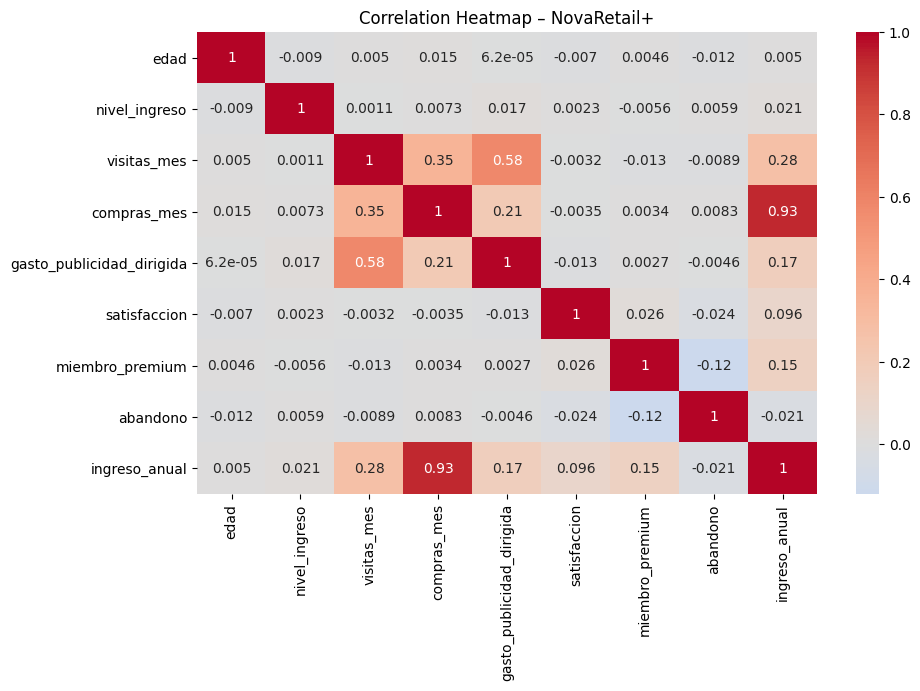

In [ ]:
# Visualizar la matriz de correlación para identificar relaciones
corr=df.corr()

plt.figure(figsize=(10,6))
sns.heatmap (corr, annot=True, cmap="coolwarm", center=0)
plt. title( "Correlation Heatmap – NovaRetail+")
plt. show()

**Diagnóstico:**

Observaciones generales (Heatmap)  
- En términos generales, el mapa de correlación muestra que la mayoría de las variables presentan correlaciones bajas o cercanas a cero, lo que indica que no existe una relación lineal fuerte entre la mayoría de ellas. Esto sugiere que las variables aportan información diferente y que no hay problemas importantes de multicolinealidad, con una excepción destacable: la relación entre `compras_mes` e `ingreso_anual`, cuya correlación es 0.93.


Observaciones respecto a `ingreso_anual`  
- La variable `ingreso_anual` destaca por presentar la correlación más alta del análisis con `compras_mes` (0.93). Esta es una relación lineal muy fuerte y sugiere que los clientes que realizan más compras al mes generan un mayor ingreso anual. Sin embargo merece ser validada para confirmar si responde al comportamiento esperado del negocio o a la forma en que se construyó la variable.

- Además tiene una correlación positiva débil con `visitas_mes` (0.28), lo que indica que visitar más el sitio no necesariamente se traduce en un incremento importante del ingreso anual, aunque existe una ligera tendencia positiva. Presenta una correlación débil con `gasto_publicidad_dirigida` (0.17) y `miembro_premium` (0.15), por lo que estas variables parecen tener una influencia limitada sobre el ingreso anual. La correlación con `edad` (0.005), `nivel_ingreso` (0.021) y `abandono` (-0.021) es prácticamente nula, indicando que no existe una relación lineal relevante entre estas variables y el ingreso anual.


### Scatterplot para pares clave

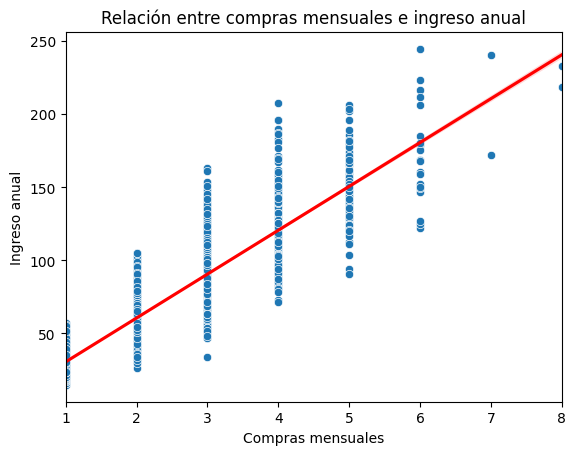

In [ ]:
# Visualizar pares de variables con relaciones moderadas o fuertes

sns.scatterplot(data=df, x="compras_mes", y="ingreso_anual")
sns.regplot(data=df, x="compras_mes", y="ingreso_anual", scatter=False, color='red')
plt.title ("Relación entre compras mensuales e ingreso anual")
plt.xlabel ("Compras mensuales")
plt. ylabel ( "Ingreso anual")
plt. show()


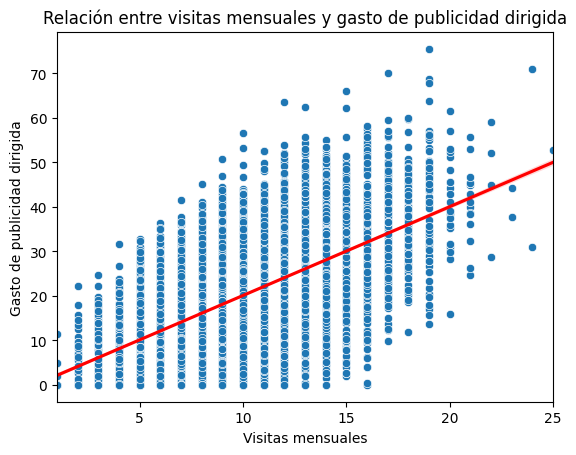

In [ ]:
sns.scatterplot(data=df, x="visitas_mes", y="gasto_publicidad_dirigida")
sns.regplot(data=df, x="visitas_mes", y="gasto_publicidad_dirigida", scatter=False, color='red')
plt.title ("Relación entre visitas mensuales y gasto de publicidad dirigida")
plt.xlabel ("Visitas mensuales")
plt. ylabel ("Gasto de publicidad dirigida")
plt. show()


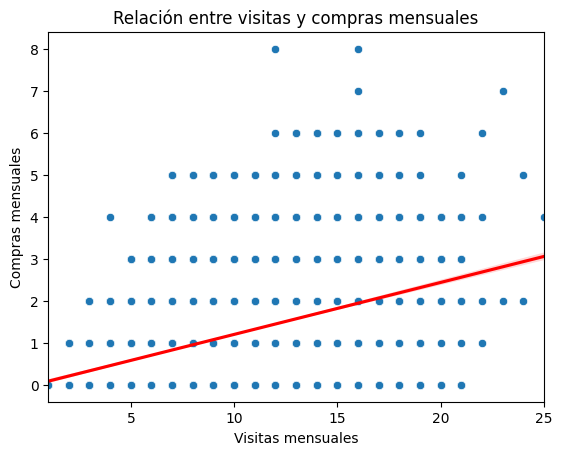

In [ ]:
sns.scatterplot(data=df, x="visitas_mes", y="compras_mes")
sns.regplot(data=df, x="visitas_mes", y="compras_mes", scatter=False, color='red')
plt.title ("Relación entre visitas y compras mensuales")
plt.xlabel ("Visitas mensuales")
plt. ylabel ("Compras mensuales")
plt. show()

**Diagnóstico:**

- Observaciones iniciales (Scatterplot)
En conjunto, los tres scatterplots muestran relaciones positivas, es decir, a medida que aumenta la variable del eje X, la variable del eje Y también tiende a incrementarse. Sin embargo, la intensidad de esta relación varía entre los gráficos. No se observan outliers extremos que se alejen claramente del comportamiento general de los datos. Asimismo, solo la relación entre `compras_mes` e `ingreso_anual` presenta indicios de una fuerte colinealidad, mientras que las otras dos relaciones muestran una mayor dispersión y una asociación menos marcada.

**1. `compras_mes` vs. `ingreso_anual`**
- Dirección: Positiva y fuerte.
- Dispersión: Baja, ya que los puntos siguen de cerca la línea de tendencia.
- Outliers: No se observan valores atípicos claramente aislados; existen algunos clientes con ingresos más altos para un mismo número de compras, pero permanecen dentro del patrón general.
- Posible colinealidad: Sí. La concentración de los puntos alrededor de la línea de regresión coincide con la alta correlación observada en el heatmap (r = 0.93), lo que indica una relación lineal muy fuerte entre ambas variables.
  
- Observación: Este gráfico confirma que el ingreso anual aumenta conforme se incrementa el número de compras mensuales, siendo la relación más consistente del análisis.


**2. `visitas_mes` vs. `gasto_publicidad_dirigida`**
- Dirección: Positiva.
- Dispersión: Media. Aunque existe una tendencia ascendente, los puntos presentan una variabilidad considerable alrededor de la línea de regresión.
- Outliers: No se identifican outliers extremos; algunos clientes muestran gastos superiores al promedio, pero siguen la tendencia general.
- Posible colinealidad: No. La dispersión observada indica una relación moderada, consistente con la correlación de 0.58 obtenida en el heatmap.

- Observación: Un mayor gasto en publicidad dirigida parece asociarse con un incremento en las visitas mensuales, aunque la relación no es suficientemente fuerte como para explicar por sí sola el comportamiento de las visitas.


**3. `visitas_mes` vs. `compras_mes`**
- Dirección: Positiva.
- Dispersión: Alta. Los puntos se encuentran ampliamente distribuidos y existe una gran variabilidad en el número de compras para un mismo número de visitas.
- Outliers: No se observan valores atípicos claramente diferenciados.
- Posible colinealidad: No. La elevada dispersión coincide con la correlación moderada-baja (r = 0.35) observada en el heatmap.

- Observación: Aunque los clientes que realizan más visitas tienden a efectuar más compras, el número de visitas por sí solo no explica el comportamiento de compra. Es probable que intervengan otros factores, como promociones, satisfacción, membresía premium o características propias del cliente.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [ ]:
# Calcular correlación entre variables relevantes
pearson = df['compras_mes'].corr(df['ingreso_anual'],method='pearson')
spearman = df['compras_mes'].corr(df['ingreso_anual'],method='spearman')
print("Pearson compras_mes vs. ingreso_anual:", pearson)
print("Spearman compras_mes vs. ingreso_anual:", spearman)

Pearson compras_mes vs. ingreso_anual: 0.934130496629332
Spearman compras_mes vs. ingreso_anual: 0.9029494228698511


In [ ]:
# Calcular correlación entre variables relevantes
pearson = df['visitas_mes'].corr(df['gasto_publicidad_dirigida'],method='pearson')
spearman = df['visitas_mes'].corr(df['gasto_publicidad_dirigida'],method='spearman')
print("Pearson visitas_mes vs. gasto_publicidad_dirigida:", pearson)
print("Spearman visitas_mes vs. gasto_publicidad_dirigida:", spearman)

Pearson visitas_mes vs. gasto_publicidad_dirigida: 0.5789472719412827
Spearman visitas_mes vs. gasto_publicidad_dirigida: 0.5592673242622609


In [ ]:
pearson = df['visitas_mes'].corr(df['compras_mes'],method='pearson')
spearman = df['visitas_mes'].corr(df['compras_mes'],method='spearman')
print("Pearson visitas_mes vs. compras_mes:", pearson)
print("Spearman visitas_mes vs. compras_mes:", spearman)

Pearson visitas_mes vs. compras_mes: 0.3538438947198978
Spearman visitas_mes vs. compras_mes: 0.33294292722789276


**Diagnóstico:**

- Observaciones de correlación
En términos generales, los coeficientes de Pearson y Spearman presentan valores muy similares en las tres comparaciones analizadas. Esto indica que las relaciones entre las variables son consistentes tanto desde una perspectiva lineal (Pearson) como monotónica (Spearman), sin evidencia de que los resultados estén siendo afectados significativamente por valores atípicos o por relaciones no lineales. Todas las correlaciones son positivas, lo que significa que, a medida que una variable aumenta, la otra también tiende a incrementarse. Sin embargo, la magnitud de la relación varía desde moderada hasta muy fuerte. Solo la relación entre `compras_mes` e `ingreso_anual` presenta indicios de una posible colinealidad debido a la alta correlación observada.


**1. `compras_mes` vs. `ingreso_anual`**
La relación es positiva y muy fuerte tanto para Pearson como para Spearman. La diferencia entre ambos coeficientes es pequeña (≈0.03), lo que sugiere que la asociación es estable y aproximadamente lineal. La magnitud de la correlación indica una posible colinealidad entre ambas variables. Esto puede ser completamente esperable si el ingreso anual depende directamente de la cantidad de compras realizadas por el cliente. Antes de utilizar ambas variables en un modelo predictivo, sería recomendable verificar que no exista redundancia entre ellas.

**2. `visitas_mes` vs. `gasto_publicidad_dirigida`**
Se observa una correlación positiva de magnitud moderada. Los valores de Pearson y Spearman son muy similares, lo que indica que la relación es consistente y no parece estar influenciada por valores extremos. No existen indicios de colinealidad, ya que la asociación, aunque clara, no es lo suficientemente alta como para considerar que ambas variables aporten información redundante. Esto sugiere que un mayor gasto en publicidad dirigida suele estar asociado con un mayor número de visitas mensuales, aunque otros factores también influyen en este comportamiento.

**3. `visitas_mes` vs. `compras_mes`**
La relación es positiva, pero de magnitud débil a moderada. La cercanía entre Pearson y Spearman indica nuevamente que la relación es estable y aproximadamente monotónica. No se observa evidencia de colinealidad, ya que la correlación es relativamente baja. Este resultado indica que un incremento en el número de visitas suele acompañarse de un aumento en las compras mensuales, aunque la cantidad de visitas por sí sola explica solo una parte del comportamiento de compra. Es probable que intervengan otras variables, como promociones, satisfacción del cliente o membresía premium.

### Punto-biserial

In [ ]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr

df = df.dropna(subset=["ingreso_anual"])
pointbiserialr(df['miembro_premium'], df['ingreso_anual'])

SignificanceResult(statistic=0.14976498378697461, pvalue=2.151761382197769e-53)

In [ ]:
pointbiserialr(df['abandono'], df['ingreso_anual'])

SignificanceResult(statistic=-0.020566188683475498, pvalue=0.03567229078067343)

**Diagnóstico:**

Observaciones Punto-biserial

**1. `miembro_premium` vs. `ingreso_anual`**
- Coeficiente: 0.150
- Dirección: Positiva.
- Magnitud: Débil.
- Valor p: 2.15 × 10⁻⁵³ (estadísticamente significativo).

- Diagnóstico: Existe una relación positiva débil entre ser miembro premium y el ingreso anual. En promedio, los clientes premium tienden a registrar ingresos anuales ligeramente superiores a los clientes que no pertenecen al programa. Sin embargo, el tamaño del efecto es pequeño, por lo que la membresía premium, por sí sola, explica una proporción limitada de la variabilidad del ingreso anual.

**2. `abandono` vs. `ingreso_anual`**
- Coeficiente: -0.021
- Dirección: Negativa.
- Magnitud: Muy débil (prácticamente nula).
- Valor p: 0.0366.

- Diagnóstico: La relación es negativa, lo que sugiere que los clientes que abandonan tienden a presentar ingresos anuales ligeramente menores. Sin embargo, la magnitud del coeficiente es prácticamente nula, por lo que esta diferencia carece de relevancia práctica, aunque resulte estadísticamente significativa debido al tamaño de la muestra.

### V de Cramér

In [ ]:
# Función para calcular V de Cramér
from scipy.stats import chi2_contingency

def cramers_v(df, tipo_dispositivo, region):
    tabla = pd.crosstab(df['tipo_dispositivo'], df['region'])

    chi2 = chi2, p, dof, expected = chi2_contingency(tabla)
    n = tabla.sum().sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) -1)))

In [ ]:
# Aplicar V de Cramér en variables relevantes
v = cramers_v(df, 'tipo_dispositivo', 'region')

print(f"V de Cramér: {v:.3f}")

V de Cramér: 0.016


**Diagnóstico:**

- Observaciones V de Cramér

El valor de 0.016 indica una asociación extremadamente débil, prácticamente inexistente, entre el tipo de dispositivo utilizado y la región del cliente. Este resultado sugiere que la distribución de los tipos de dispositivo es muy similar en todas las regiones y que conocer la región de un cliente no aporta información relevante para predecir el dispositivo que utiliza, ni viceversa.


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

##Hallazgos:

### Hallazgo 1: La frecuencia de compra está fuertemente asociada con el ingreso anual

**Evidencia visual:**   
- El heatmap muestra la correlación más alta entre `compras_mes` e `ingreso_anual`.
- El scatterplot evidencia una clara tendencia ascendente con baja dispersión alrededor de la línea de regresión.

**Evidencia numérica:**
- Correlación de Pearson: 0.934.
- Correlación de Spearman: 0.903.

**Interpretación**  
Los clientes que realizan un mayor número de compras al mes tienden a registrar mayores ingresos anuales. La relación es muy fuerte y consistente tanto para una asociación lineal como monotónica.

**No podemos afirmar**  
No podemos concluir que incrementar el número de compras provoque directamente un aumento del ingreso anual, ya que se trata de un análisis correlacional y ambas variables podrían estar relacionadas por otros factores o incluso por la forma en que fue calculado el ingreso anual.

**Implicación de negocio**  
Conviene identificar las características de los clientes con mayor frecuencia de compra para diseñar estrategias que incentiven la recurrencia, como programas de fidelización, promociones personalizadas o recomendaciones de productos.

### Hallazgo 2: La publicidad dirigida se asocia con un mayor nivel de visitas, pero no explica completamente el comportamiento del cliente

**Evidencia visual:**
- El scatterplot entre `visitas_mes` y `gasto_publicidad_dirigida` presenta una tendencia positiva, aunque con una dispersión moderada.
  
**Evidencia numérica:**
- Pearson: 0.579.
- Spearman: 0.559.
  
**Interpretación**  
Existe una asociación positiva moderada entre el gasto en publicidad dirigida y el número de visitas mensuales. Los clientes con mayor inversión publicitaria tienden a registrar más visitas, aunque la relación presenta una variabilidad considerable.

**No podemos afirmar**  
No es posible afirmar que la publicidad dirigida sea la causa del incremento en las visitas, ya que pueden intervenir otros factores como promociones, estacionalidad, preferencias del cliente o campañas de otros canales. Además, la variable incluye valores 0 cuyo significado no pudo confirmarse (ausencia de gasto o dato faltante), por lo que la magnitud de la relación podría variar.

**Implicación de negocio**  
La publicidad dirigida parece ser una herramienta útil para atraer tráfico, pero su desempeño debería evaluarse junto con otras métricas, como la conversión a compra y el retorno de la inversión (ROI), antes de incrementar el presupuesto destinado a campañas.

### Hallazgo 3: El comportamiento de los clientes es similar entre regiones respecto al dispositivo utilizado

**Evidencia visual:**
- La distribución de `tipo_dispositivo` muestra un predominio del uso de dispositivos móviles en todas las categorías analizadas.
- El análisis de asociación mediante V de Cramér no evidencia diferencias relevantes entre regiones.
  
**Evidencia numérica:**
- V de Cramér (tipo_dispositivo vs. region): 0.016.
  
**Interpretación**  
La región del cliente prácticamente no está asociada con el tipo de dispositivo utilizado, lo que indica que el patrón de uso de móviles, computadoras y tabletas es muy similar entre las distintas regiones.

**No podemos afirmar**  
No podemos concluir que la región influya en la elección del dispositivo, ni que modificar estrategias por región cambie el comportamiento de uso de los clientes.

**Implicación de negocio**  
Las estrategias de optimización de la experiencia digital pueden diseñarse de forma general para todas las regiones, priorizando especialmente la experiencia en dispositivos móviles, que representan la mayor proporción de usuarios, sin necesidad de desarrollar interfaces diferenciadas por ubicación geográfica.

## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones**
- 1. El análisis es correlacional, no causal
Las técnicas utilizadas (heatmap, correlaciones de Pearson, Spearman, punto-biserial y V de Cramér) permiten identificar asociaciones entre variables, pero no demuestran relaciones de causa y efecto. Por ello, no es posible afirmar que una variable provoque cambios en otra sin realizar análisis adicionales o estudios experimentales.
- 2. Tratamiento de valores faltantes en `ingreso_anual`
Esta columna presentó una cantidad importante de valores faltantes (aproximadamente el 30% del conjunto de datos), que fueron eliminados mediante dropna(). Esto reduce el tamaño de la muestra y podría introducir sesgo si los datos faltantes no ocurrieron completamente al azar (MCAR).
- 3. Análisis bivariado
La mayor parte del análisis se realizó comparando dos variables a la vez. Este enfoque no considera la influencia simultánea de otras variables que podrían afectar los resultados (por ejemplo, edad, nivel de ingreso, satisfacción o membresía premium). Para obtener una comprensión más completa del comportamiento de los clientes sería recomendable complementar el estudio con análisis multivariados o modelos predictivos.


### **Próximos pasos**

- 1. Profundizar en la segmentación de clientes
Segmentar a los clientes según variables como frecuencia de compra, ingreso anual, membresía premium, satisfacción y comportamiento de visitas para identificar perfiles con características similares. Esto permitirá reconocer los segmentos de mayor valor y diseñar estrategias comerciales específicas para cada uno.


- 2. Desarrollar un modelo predictivo de abandono (Churn)
Construir un modelo de clasificación que estime la probabilidad de que un cliente abandone la empresa utilizando variables como compras mensuales, visitas, satisfacción, membresía premium, publicidad dirigida e ingreso anual. Esto facilitaría identificar clientes en riesgo y aplicar acciones de retención de manera anticipada.


- 3. Evaluar el impacto de las estrategias comerciales
Realizar un análisis más profundo sobre la efectividad de la publicidad dirigida y del programa de membresía premium, incorporando métricas como la tasa de conversión, el valor de vida del cliente (Customer Lifetime Value, CLV) o el retorno de la inversión (ROI). De esta forma se podrá determinar qué estrategias generan un mayor valor para el negocio y optimizar la asignación de recursos.